In [1]:
import numpy as np
import matplotlib.pyplot as plt

import os
import pandas as pd
# import colorednoise as cn
import scipy.stats as stats
import random

In [2]:
def plot_shifts(data_stream,idx_list,drift_detected,label,color,text= True):
    plt.figure(figsize=(10,5))
    plt.plot(data_stream)
    plt.plot(idx_list, drift_detected, 'o', label = label, color = color)
    if text:
        for i in range(len(idx_list)):
            plt.text(idx_list[i], drift_detected[i], str(idx_list[i]), fontsize=12)
  

    plt.xlabel('Time')
    plt.ylabel('Value')
    plt.legend()
    # plt.savefig(f'ADWIN_FIGS/{label}_Abrupt_Sergi.png')

In [3]:
#read txt file as a list
def read_txt_file(file_name):
    with open(file_name) as f:
        lines = f.readlines()
    return [int(x.strip()) for x in lines]

# Datasets

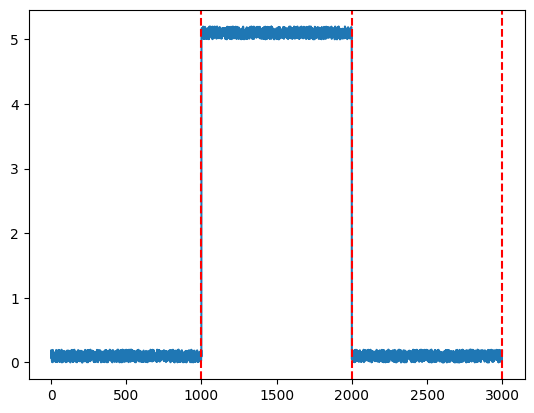

In [4]:
random_state = np.random.RandomState(seed=42)
part_1 = random_state.uniform(0,0.2, 1000)
part_2 = random_state.uniform(5,5.2, 1000)
part_3 = random_state.uniform(0, 0.2, 1000)

x = np.concatenate([part_1, part_2, part_3])
data_stream = x
plt.plot(data_stream)
plt.axvline(x=len(part_1), color='r', linestyle='--')
plt.axvline(x=len(part_1)+len(part_2), color='r', linestyle='--')
plt.axvline(x=len(part_1)+len(part_2)+len(part_3), color='r', linestyle='--')

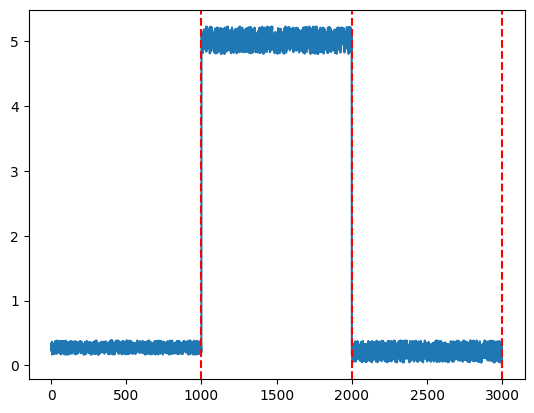

In [5]:
rng = np.random.RandomState(seed=random.randint(0, 1000))
mu1 = rng.uniform(0, 0.2)
mu2 = rng.uniform(4.8, 5)
mu3 = rng.uniform(0, 0.2)

s1 = rng.uniform(0.2, 0.5)
s2 = rng.uniform(5.2, 5.5)
s3 = rng.uniform(0.2, 0.5)
                 
part_1 = random_state.uniform(mu1, s1, 1000)
part_2 = random_state.uniform(mu2, s2, 1000)
part_3 = random_state.uniform(mu3, s3, 1000)

x = np.concatenate([part_1, part_2, part_3])
data_stream = x
plt.plot(data_stream)
plt.axvline(x=len(part_1), color='r', linestyle='--')
plt.axvline(x=len(part_1)+len(part_2), color='r', linestyle='--')
plt.axvline(x=len(part_1)+len(part_2)+len(part_3), color='r', linestyle='--')

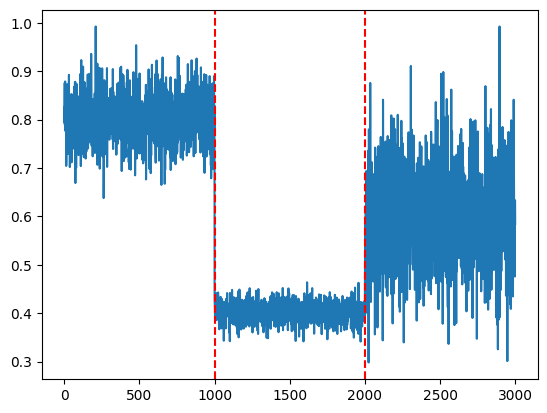

In [6]:
random_state = np.random.RandomState(seed=42)
part_1 = random_state.normal(0.8, 0.05, 1000)
part_2 = random_state.normal(0.4, 0.02, 1000)
part_3 = random_state.normal(0.6, 0.1, 1000)
x = np.concatenate([part_1, part_2, part_3])
data_stream = x
plt.plot(data_stream)
plt.axvline(x=len(part_1), color='r', linestyle='--')
plt.axvline(x=len(part_1)+len(part_2), color='r', linestyle='--')


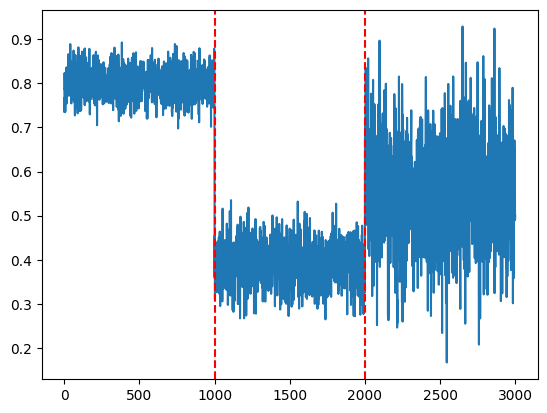

In [7]:
random_state = np.random.RandomState(seed=random.randint(0, 1000))
mu1 = random_state.uniform(0.7, 0.9)
mu2 = random_state.uniform(0.3, 0.5)
mu3 = random_state.uniform(0.5, 0.7)

sigma1 = random_state.uniform(0.03, 0.08)
sigma2 = random_state.uniform(0.01, 0.05)
sigma3 = random_state.uniform(0.05, 0.15)

part_1 = random_state.normal(mu1, sigma1, 1000)
part_2 = random_state.normal(mu2, sigma2, 1000)
part_3 = random_state.normal(mu3, sigma3, 1000)
x = np.concatenate([part_1, part_2, part_3])
data_stream = x
plt.plot(data_stream)
plt.axvline(x=len(part_1), color='r', linestyle='--')
plt.axvline(x=len(part_1)+len(part_2), color='r', linestyle='--')


# Generation

In [8]:
min_interval = 1000
max_interval = 5000

In [9]:
def generate_random_noisy(seed):
    rng = np.random.RandomState(seed)

    mu1 = rng.uniform(0.7, 0.9)
    mu2 = rng.uniform(0.3, 0.5)
    mu3 = rng.uniform(0.5, 0.7)

    sigma1 = rng.uniform(0.03, 0.08)
    sigma2 = rng.uniform(0.01, 0.05)
    sigma3 = rng.uniform(0.05, 0.15)

    part_1 = rng.normal(mu1, sigma1, random.randint(min_interval, max_interval))
    part_2 = rng.normal(mu2, sigma2, random.randint(min_interval, max_interval))
    part_3 = rng.normal(mu3, sigma3, random.randint(min_interval, max_interval))

    series = np.concatenate([part_1, part_2, part_3])

    # Drift labels = change points
    drift_labels = [
        len(part_1),
        len(part_1) + len(part_2)
    ]

    return series, drift_labels


filename = f'time_series_random_noisy_100.csv'
if os.path.exists(filename):
    os.remove(filename)

filename_labels = f'drift_labels_random_noisy_100.csv'
if os.path.exists(filename_labels):
    os.remove(filename_labels)
    
all_series = []
all_labels = []

# Generate 1000 time series
for seed in range(42, 142):
    series, labels = generate_random_noisy(seed)

    with open(f"{filename}", "a") as file:
        np.savetxt(file, [series], delimiter=",", fmt="%.6f")
    with open(f"{filename_labels}", "a") as file:
        np.savetxt(file, [labels], delimiter=",", fmt="%.6f") 

In [10]:
def generate_random_simple(seed):
    rng = np.random.RandomState(seed)

    mu1 = rng.uniform(0, 0.2)
    mu2 = rng.uniform(4.8, 5)
    mu3 = rng.uniform(0, 0.2)

    s1 = rng.uniform(0.2, 0.5)
    s2 = rng.uniform(5.2, 5.5)
    s3 = rng.uniform(0.2, 0.5)
                 

    part_1 = rng.uniform(mu1,s1, random.randint(min_interval, max_interval))
    part_2 = rng.uniform(mu2,s2, random.randint(min_interval, max_interval))
    part_3 = rng.uniform(mu3,s3, random.randint(min_interval, max_interval))

    series = np.concatenate([part_1, part_2, part_3])

    # Drift labels = change points
    drift_labels = [
        len(part_1),
        len(part_1) + len(part_2)
    ]

    return series, drift_labels

filename = f'time_series_random_simple_100.csv'
if os.path.exists(filename):
    os.remove(filename)

filename_labels = f'drift_labels_random_simple_100.csv'
if os.path.exists(filename_labels):
    os.remove(filename_labels)

all_series = []
all_labels = []

# Generate 1000 time series
for seed in range(42, 142):
    series, labels = generate_random_simple(seed)

    with open(f"{filename}", "a") as file:
        np.savetxt(file, [series], delimiter=",", fmt="%.6f")
    with open(f"{filename_labels}", "a") as file:
        np.savetxt(file, [labels], delimiter=",", fmt="%.6f") 